# LLM Classification Finetuning - Starter Notebook

**Task:** given a user prompt and two chatbot responses (Chatbot Arena), predict which one a human preferred: `winner_model_a`, `winner_model_b` or `winner_tie`.

**Metric:** multi-class log loss (lower is better; uniform guess = ln 3 = 1.0986).

**This notebook builds a fast CPU baseline:**
1. Parse the JSON-encoded multi-turn conversations
2. Quick EDA (class balance, length bias)
3. Hand-crafted features (length, formatting, refusals) + TF-IDF similarity + SVD embeddings
4. LightGBM with A/B swap augmentation and swap test-time augmentation
5. 5-fold CV and `submission.csv`

The last section lists directions for transformer / LLM fine-tuning.

In [6]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

warnings.filterwarnings('ignore')

SEED = 42
N_FOLDS = 5
DEBUG = False  # True -> subsample train for quick iteration


DATA_DIR = './data/llm-classification-finetuning' 


TARGETS = ['winner_model_a', 'winner_model_b', 'winner_tie']

## 1. Load data

`prompt`, `response_a` and `response_b` are JSON-encoded lists (one entry per turn, some `null`). We join turns into one string per column and keep the number of turns.

In [7]:
train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
sample_sub = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')

if DEBUG:
    train = train.sample(5000, random_state=SEED).reset_index(drop=True)


def parse_turns(s):
    try:
        t = json.loads(s)
    except Exception:
        return [str(s)]
    if not isinstance(t, list):
        t = [t]
    return ['' if x is None else str(x) for x in t]


for df in (train, test):
    for col in ['prompt', 'response_a', 'response_b']:
        turns = df[col].map(parse_turns)
        df[col + '_text'] = turns.str.join('\n\n')
        if col == 'prompt':
            df['n_turns'] = turns.str.len()

print('train:', train.shape, ' test:', test.shape)
train.head(3)

train: (57477, 13)  test: (3, 8)


,id,model_a,model_b,prompt,response_a,response_b,winner_model_a,winner_model_b,winner_tie,prompt_text,n_turns,response_a_text,response_b_text
0,30192,gpt-4-1106-preview,gpt-4-0613,"[""Is it morally right to try to have a certain...","[""The question of whether it is morally right ...","[""As an AI, I don't have personal beliefs or o...",1,0,0,Is it morally right to try to have a certain p...,2,The question of whether it is morally right to...,"As an AI, I don't have personal beliefs or opi..."
1,53567,koala-13b,gpt-4-0613,"[""What is the difference between marriage lice...","[""A marriage license is a legal document that ...","[""A marriage license and a marriage certificat...",0,1,0,What is the difference between marriage licens...,3,A marriage license is a legal document that al...,A marriage license and a marriage certificate ...
2,65089,gpt-3.5-turbo-0613,mistral-medium,"[""explain function calling. how would you call...","[""Function calling is the process of invoking ...","[""Function calling is the process of invoking ...",0,0,1,explain function calling. how would you call a...,1,Function calling is the process of invoking or...,Function calling is the process of invoking a ...


## 2. Quick EDA

winner_model_a    0.3491
winner_model_b    0.3419
winner_tie        0.3090
dtype: float64
Uniform log loss: 1.0986
Prior   log loss: 1.0972


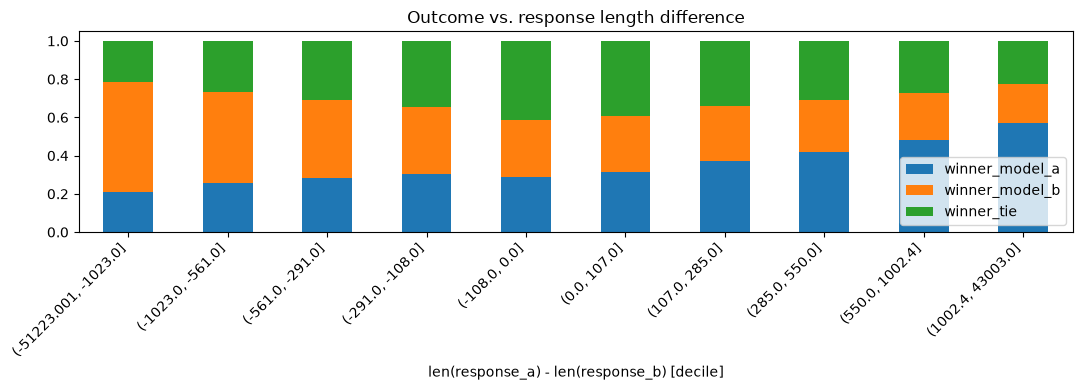

In [8]:
y = train[TARGETS].values.argmax(axis=1)  # 0 = A wins, 1 = B wins, 2 = tie
prior = train[TARGETS].mean().values

print(train[TARGETS].mean().round(4))
print('Uniform log loss:', round(log_loss(y, np.full((len(y), 3), 1 / 3), labels=[0, 1, 2]), 4))
print('Prior   log loss:', round(log_loss(y, np.tile(prior, (len(y), 1)), labels=[0, 1, 2]), 4))

# Length bias: humans tend to prefer the longer answer
len_diff = train['response_a_text'].str.len() - train['response_b_text'].str.len()
bins = pd.qcut(len_diff, 10, duplicates='drop')
ax = train.groupby(bins, observed=True)[TARGETS].mean().plot(kind='bar', stacked=True, figsize=(11, 4))
ax.set_xlabel('len(response_a) - len(response_b) [decile]')
ax.set_title('Outcome vs. response length difference')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 3. Features

Features are computed per side (A and B) plus their difference, so swapping A and B yields a mirrored feature vector. That makes swap augmentation trivial.

In [9]:
REFUSAL_RE = r'(?i)\b(?:sorry|apologi[sz]e|i cannot|as an ai)'


def text_feats(s):
    words = s.str.split()
    n_words = words.str.len().fillna(0)
    n_chars = s.str.len()
    f = pd.DataFrame({
        'chars': n_chars,
        'log_chars': np.log1p(n_chars),
        'words': n_words,
        'lines': s.str.count('\n') + 1,
        'paragraphs': s.str.count('\n\n') + 1,
        'bullets': s.str.count(r'(?m)^\s*(?:[-*]|\d+[.)])\s'),
        'headers': s.str.count(r'(?m)^#{1,6}\s'),
        'code_blocks': s.str.count('```') // 2,
        'bold': s.str.count(r'\*\*[^*\n]+\*\*'),
        'urls': s.str.count('http'),
        'questions': s.str.count(r'\?'),
        'exclaims': s.str.count('!'),
        'digit_ratio': s.str.count(r'\d') / (n_chars + 1),
        'upper_ratio': s.str.count(r'[A-Z]') / (n_chars + 1),
        'unique_word_ratio': words.map(lambda w: len(set(w)) / (len(w) + 1)),
        'avg_word_len': n_chars / (n_words + 1),
        'refusal': s.str.contains(REFUSAL_RE).astype(int),
        'empty': (s.str.strip().str.len() == 0).astype(int),
    }, index=s.index)
    return f.astype('float32')

TF-IDF features: cosine similarity prompt-A, prompt-B and A-B (near-identical answers hint at ties), plus a 32-dim SVD embedding of the prompt and of (A - B).

In [10]:
all_text = pd.concat([train['prompt_text'], train['response_a_text'], train['response_b_text']])
tfidf = TfidfVectorizer(max_features=50000, min_df=3, sublinear_tf=True, dtype=np.float32).fit(all_text)
svd = TruncatedSVD(n_components=32, random_state=SEED).fit(
    tfidf.transform(pd.concat([train['response_a_text'], train['response_b_text']]))
)


def rowdot(X, Y):
    # TF-IDF rows are L2-normalised, so the dot product is the cosine similarity
    return np.asarray(X.multiply(Y).sum(axis=1)).ravel()


def build_parts(df):
    df = df.reset_index(drop=True)
    P = tfidf.transform(df['prompt_text'])
    A = tfidf.transform(df['response_a_text'])
    B = tfidf.transform(df['response_b_text'])
    return {
        'FP': text_feats(df['prompt_text']).add_prefix('p_').assign(n_turns=df['n_turns'].values),
        'FA': text_feats(df['response_a_text']),
        'FB': text_feats(df['response_b_text']),
        'sim_pa': rowdot(P, A), 'sim_pb': rowdot(P, B), 'sim_ab': rowdot(A, B),
        'SP': svd.transform(P), 'SA': svd.transform(A), 'SB': svd.transform(B),
    }


def assemble(parts, swap=False):
    FA, FB, SA, SB = parts['FA'], parts['FB'], parts['SA'], parts['SB']
    sim_a, sim_b = parts['sim_pa'], parts['sim_pb']
    if swap:
        FA, FB, SA, SB, sim_a, sim_b = FB, FA, SB, SA, sim_b, sim_a
    idx = FA.index
    return pd.concat([
        parts['FP'],
        FA.add_prefix('a_'),
        FB.add_prefix('b_'),
        (FA - FB).add_prefix('diff_'),
        pd.DataFrame({'sim_pa': sim_a, 'sim_pb': sim_b, 'sim_diff': sim_a - sim_b,
                      'sim_ab': parts['sim_ab']}, index=idx),
        pd.DataFrame(parts['SP'], index=idx).add_prefix('svd_p_'),
        pd.DataFrame(SA - SB, index=idx).add_prefix('svd_diff_'),
    ], axis=1).astype('float32')


train_parts = build_parts(train)
X_tr = assemble(train_parts)
X_tr_sw = assemble(train_parts, swap=True)
print('feature matrix:', X_tr.shape)

feature matrix: (57477, 141)


## 4. LightGBM with swap augmentation

- **Train time:** every training row is used twice, as-is and with A/B swapped (labels A-wins and B-wins exchanged).
- **Test time:** predict both orientations and average after mapping the swapped probabilities back.

Folds are split on the original rows, so a row and its swapped twin never straddle train/validation.

In [11]:
SWAP = np.array([1, 0, 2])  # exchanges A-win and B-win
y_sw = SWAP[y]


def predict_tta(model, X, X_sw):
    return (model.predict_proba(X) + model.predict_proba(X_sw)[:, SWAP]) / 2


params = dict(
    objective='multiclass', num_class=3,
    learning_rate=0.03, n_estimators=5000,
    num_leaves=31, min_child_samples=40,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
    reg_lambda=1.0, random_state=SEED, verbose=-1,
)

oof = np.zeros((len(train), 3))
models = []
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

for fold, (tr, va) in enumerate(skf.split(X_tr, y)):
    X_fit = pd.concat([X_tr.iloc[tr], X_tr_sw.iloc[tr]], ignore_index=True)
    y_fit = np.concatenate([y[tr], y_sw[tr]])

    model = lgb.LGBMClassifier(**params)
    model.fit(X_fit, y_fit,
              eval_set=[(X_tr.iloc[va], y[va])],
              callbacks=[lgb.early_stopping(100, verbose=False)])

    oof[va] = predict_tta(model, X_tr.iloc[va], X_tr_sw.iloc[va])
    print(f'fold {fold}: log loss = {log_loss(y[va], oof[va], labels=[0, 1, 2]):.4f} (best_iter = {model.best_iteration_})')
    models.append(model)

print(f'CV log loss: {log_loss(y, oof, labels=[0, 1, 2]):.4f}')

fold 0: log loss = 1.0044 (best_iter = 1058)
fold 1: log loss = 0.9998 (best_iter = 1256)
fold 2: log loss = 0.9997 (best_iter = 958)
fold 3: log loss = 0.9995 (best_iter = 769)
fold 4: log loss = 1.0045 (best_iter = 1197)
CV log loss: 1.0016


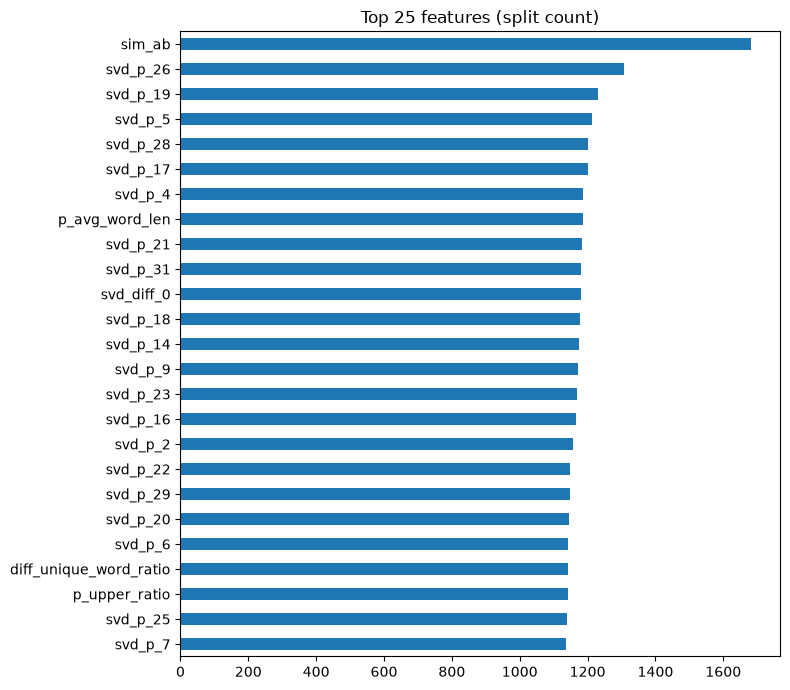

In [12]:
importance = pd.Series(np.mean([m.feature_importances_ for m in models], axis=0),
                       index=X_tr.columns).sort_values(ascending=False)
ax = importance.head(25).plot.barh(figsize=(8, 7), title='Top 25 features (split count)')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 5. Predict and submit

The public `test.csv` is tiny; the hidden test set replaces it when the notebook is re-run at submission time. Only raw columns are used, so this works unchanged.

In [13]:
test_parts = build_parts(test)
X_te = assemble(test_parts)
X_te_sw = assemble(test_parts, swap=True)

pred = np.mean([predict_tta(m, X_te, X_te_sw) for m in models], axis=0)

submission = pd.DataFrame({'id': test['id'].values})
for i, col in enumerate(TARGETS):
    submission[col] = pred[:, i]
submission = submission[sample_sub.columns]
submission.to_csv('submission.csv', index=False)
submission.head()

,id,winner_model_a,winner_model_b,winner_tie
0,136060,0.183313,0.393839,0.422848
1,211333,0.459779,0.307497,0.232723
2,1233961,0.153757,0.595257,0.250986


## 6. Where to go next

This baseline mostly captures style signals (length, formatting, refusals). Stronger solutions read the text:

- **Fine-tune a cross-encoder** (e.g. DeBERTa-v3) on `prompt [SEP] response_a [SEP] response_b` with a 3-way head; truncate each part sensibly, use swap augmentation and swap TTA.
- **LoRA / QLoRA fine-tune a decoder LLM** (Gemma, Llama, Qwen class) as a classifier; mind the notebook runtime limit.
- **Ensemble / stack** the LLM logits with this LightGBM on OOF predictions; the length and format features stay complementary.
- **Calibrate** probabilities (temperature scaling on OOF); log loss punishes over-confidence.
- **Extra data:** public LMSYS Arena datasets (deduplicate against train).
- Check the competition's Code Requirements (internet access, runtime limit) before submitting.